# Methods without a tree: KMeans and Gaussian mixtures

The adaptive cut needs a tree. Flat methods (KMeans, Gaussian mixtures, ...) do not give one,
but they can be used to over-cluster the data into many small clusters. A Ward tree over the
small clusters, scored by the points under each node, then lets the adaptive cut decide which
small clusters to merge. Each branch is merged up to its own height.

This notebook needs `pip install adaptive_cut scikit-learn matplotlib`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.cluster.hierarchy import linkage
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score as ari
from sklearn.mixture import GaussianMixture

import adaptive_cut as ac

In [2]:
def blobs(seed=0):
    """Three tight blobs (150 points each) next to two wide ones (300 each)."""
    rng = np.random.default_rng(seed)
    centers = np.array([[0, 0], [1.2, 0], [0.6, 1.0], [8, 0], [4, 7]])
    std = np.array([0.25, 0.25, 0.25, 1.6, 1.6])
    y = np.repeat(np.arange(5), [150, 150, 150, 300, 300])
    X = centers[y] + std[y, None] * rng.standard_normal((len(y), 2))
    return X, y


X, y = blobs(seed=0)

## A tree over small clusters

`tree_of_clusters` builds a Ward tree over the centres of the small clusters and scores every
node by the Gaussian BIC of all the points under it (the same score as `ac.gaussian_scores`).
The adaptive cut of this tree is a partition of the small clusters; `labels[micro]` maps it
back to the points.

In [3]:
def tree_of_clusters(X, micro, var_floor=0.01):
    """Ward tree over the clusters in `micro` and the Gaussian BIC score of each node."""
    k = micro.max() + 1
    groups = [np.flatnonzero(micro == j) for j in range(k)]
    centers = np.array([X[g].mean(axis=0) for g in groups])
    Z = linkage(centers, "ward")
    N, d = X.shape
    floor = var_floor * X.var(axis=0)

    def bic(leaves):
        P = X[np.concatenate([groups[j] for j in leaves])]
        m = len(P)
        vhat = P.var(axis=0)
        v = np.maximum(vhat, floor)
        return (
            -0.5 * m * (np.log(2 * np.pi * v) + vhat / v).sum()
            + m * np.log(m)
            - 0.5 * (2 * d + 1) * np.log(N)
        )

    return Z, ac.node_scores(Z, bic)

## KMeans with 50 clusters, then the adaptive cut

In [4]:
micro = KMeans(50, n_init=3, random_state=0).fit_predict(X)
Z, scores = tree_of_clusters(X, micro)
level = ac.best_level_cut(Z, scores)
res = ac.adaptive_cut(Z, scores, T="auto", rng=0)

kmeans = KMeans(5, n_init=10, random_state=0).fit_predict(X)
fits = [GaussianMixture(k, random_state=0).fit(X) for k in range(1, 16)]
gmm = min(fits, key=lambda g: g.bic(X)).predict(X)

results = {
    "KMeans, true k = 5": kmeans,
    "Gaussian mixture, k by BIC": gmm,
    "KMeans(50) + single-level cut": level.labels[micro],
    "KMeans(50) + adaptive cut": res.labels[micro],
}
for name, labels in results.items():
    print(f"{name:>30}: {len(np.unique(labels)):2d} clusters, ARI {ari(y, labels):.2f}")

            KMeans, true k = 5:  5 clusters, ARI 0.43
    Gaussian mixture, k by BIC:  7 clusters, ARI 0.57
 KMeans(50) + single-level cut:  3 clusters, ARI 0.70
     KMeans(50) + adaptive cut:  5 clusters, ARI 0.96


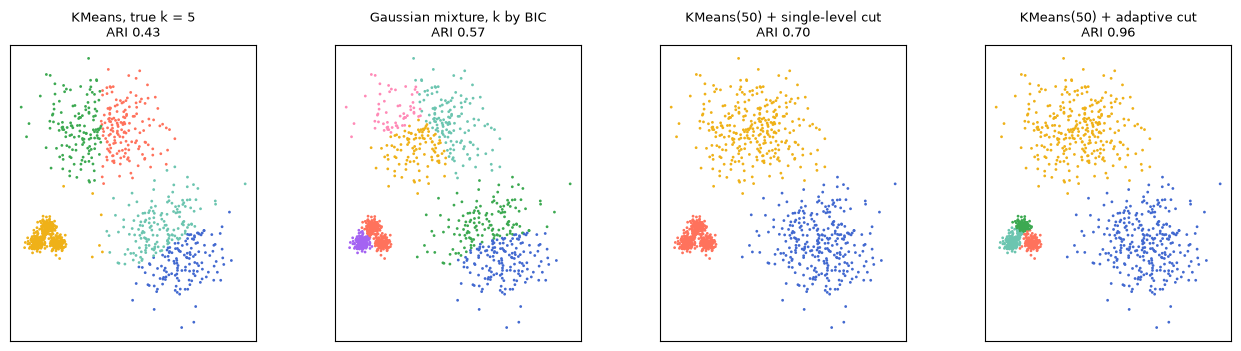

In [5]:
COLORS = np.array(
    [
        "#4269d0",
        "#efb118",
        "#ff725c",
        "#6cc5b0",
        "#3ca951",
        "#ff8ab7",
        "#a463f2",
        "#97bbf5",
        "#9c6b4e",
        "#9498a0",
    ]
)


def scatter(ax, X, labels, title):
    labels = np.asarray(labels)
    c = np.where(labels < 0, "#d0d0d0", COLORS[np.maximum(labels, 0) % len(COLORS)])
    ax.scatter(X[:, 0], X[:, 1], s=4, c=c, linewidths=0)
    ax.set_title(title, fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_aspect("equal")


fig, axes = plt.subplots(1, 4, figsize=(13, 3.4), layout="constrained")
for ax, (name, labels) in zip(axes, results.items()):
    scatter(ax, X, labels, f"{name}\nARI {ari(y, labels):.2f}")

## Gaussian mixture components as small clusters

The same works with any method that returns labels, for example a Gaussian mixture with 30
components.

In [6]:
micro = GaussianMixture(30, random_state=0).fit(X).predict(X)
micro = np.unique(micro, return_inverse=True)[1]  # drop empty components
Z, scores = tree_of_clusters(X, micro)
res = ac.adaptive_cut(Z, scores, T="auto", rng=0)
labels = res.labels[micro]
print(
    f"GaussianMixture(30) + adaptive cut: {len(np.unique(labels))} clusters, ARI {ari(y, labels):.2f}"
)

GaussianMixture(30) + adaptive cut: 5 clusters, ARI 0.98
